# 06.7 · t-SNE and UMAP: pictures of high-dimensional data (optional)

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/06-unsupervised/07-tsne-umap/lesson.ipynb)

Read the [README](README.md) first. This notebook draws the same 64-dimensional digits with PCA and with t-SNE, shows what perplexity does, and then shows how t-SNE pictures can mislead.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")

from sklearn.datasets import load_digits
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
X_dig, y_dig = load_digits(return_X_y=True)
print(X_dig.shape)

(1797, 64)


## 1. PCA vs t-SNE on the same data

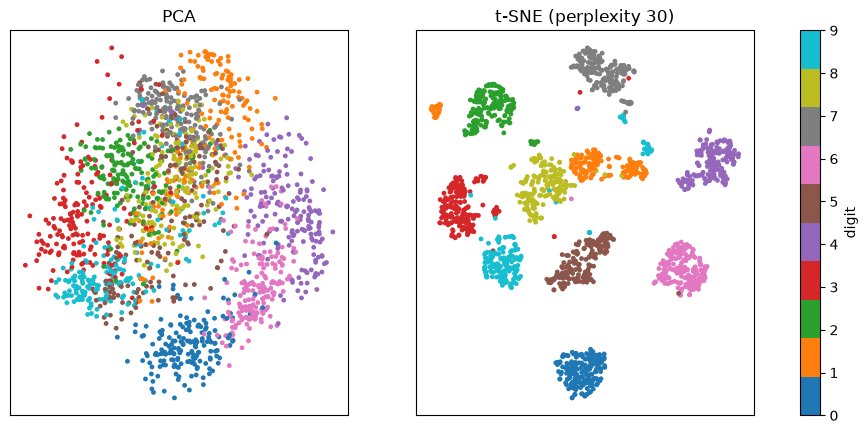

In [2]:
xy_pca = PCA(n_components=2).fit_transform(X_dig)
xy_tsne = TSNE(n_components=2, perplexity=30, random_state=0).fit_transform(X_dig)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for a, xy, title in [(ax[0], xy_pca, "PCA"), (ax[1], xy_tsne, "t-SNE (perplexity 30)")]:
    sc = a.scatter(xy[:, 0], xy[:, 1], c=y_dig, cmap="tab10", s=6)
    a.set_title(title); a.set_xticks([]); a.set_yticks([])
fig.colorbar(sc, ax=ax, label="digit"); plt.show()

PCA keeps the overall spread but the digits overlap. t-SNE pulls each digit into its own island. That is its job: **keep neighbours together**. The colours are only for us; t-SNE never saw the labels.

How well does each picture keep each digit's neighbours? Count how often a point's nearest neighbour in the 2-D picture has the same label.

In [3]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score
for name, xy in [("PCA", xy_pca), ("t-SNE", xy_tsne), ("all 64 pixels", X_dig)]:
    acc = cross_val_score(KNeighborsClassifier(1), xy, y_dig, cv=5).mean()
    print(f"{name:>14}: 1-nearest-neighbour agrees with the label {acc:.1%} of the time")

           PCA: 1-nearest-neighbour agrees with the label 57.0% of the time
         t-SNE: 1-nearest-neighbour agrees with the label 96.9% of the time
 all 64 pixels: 1-nearest-neighbour agrees with the label 96.4% of the time


## 2. Perplexity: how many neighbours each point cares about

Perplexity is roughly the number of neighbours t-SNE tries to keep close. Small values focus on tiny local groups; large values care more about broader structure.

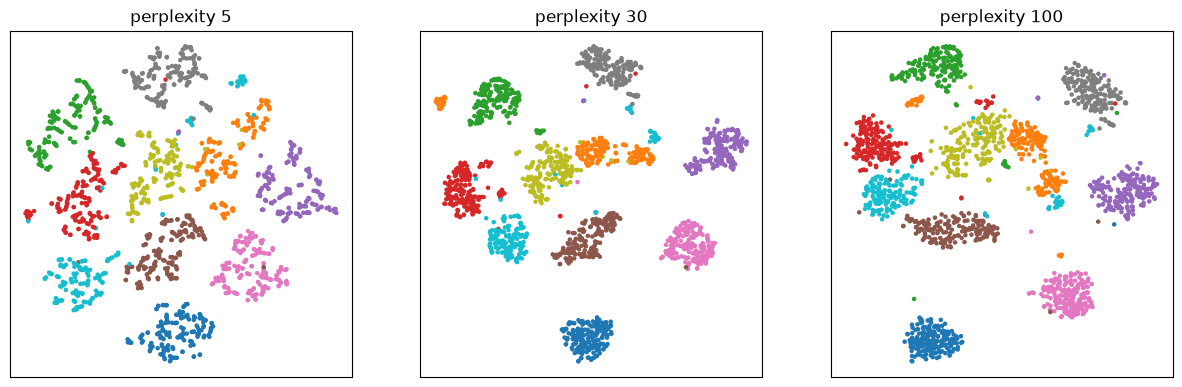

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
for a, perp in zip(ax, [5, 30, 100]):
    xy = TSNE(perplexity=perp, random_state=0).fit_transform(X_dig)
    a.scatter(xy[:, 0], xy[:, 1], c=y_dig, cmap="tab10", s=5)
    a.set_title(f"perplexity {perp}"); a.set_xticks([]); a.set_yticks([])
plt.show()

Same data, three different pictures. None is "the truth". Always try a few perplexities before believing a shape.

## 3. How t-SNE pictures mislead

Two groups in 10-D: one tight (std 1, 300 points), one huge and spread out (std 10, 300 points), far apart.

In [5]:
rng = np.random.default_rng(0)
tight = rng.normal(0, 1, size=(300, 10))
loose = rng.normal(0, 10, size=(300, 10)) + 100
both = np.vstack([tight, loose]); group = np.array([0] * 300 + [1] * 300)

xy = TSNE(perplexity=30, random_state=0).fit_transform(both)
for g, name in [(0, "tight"), (1, "loose")]:
    spread_orig = both[group == g].std(axis=0).mean()
    spread_tsne = xy[group == g].std(axis=0).mean()
    print(f"{name:>5}: spread in 10-D {spread_orig:5.1f}   spread in t-SNE picture {spread_tsne:5.1f}")

tight: spread in 10-D   1.0   spread in t-SNE picture   6.6
loose: spread in 10-D   9.9   spread in t-SNE picture   6.5


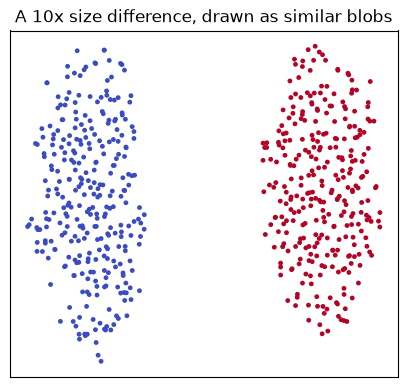

In [6]:
plt.figure(figsize=(5, 4.5))
plt.scatter(xy[:, 0], xy[:, 1], c=group, cmap="coolwarm", s=6)
plt.title("A 10x size difference, drawn as similar blobs"); plt.xticks([]); plt.yticks([]); plt.show()

In the real data one group is ten times wider than the other. In the t-SNE picture they come out about the same size. The distance *between* the two blobs is also arbitrary: re-run with another seed or perplexity and it changes.

**Rules for reading a t-SNE plot**

1. Points close together are similar. That part you can trust.
2. Cluster **sizes** mean nothing.
3. Distances **between** clusters mean little.
4. Never feed t-SNE coordinates into a model: there is no `transform` for new rows, and the axes have no meaning.

## 4. UMAP

UMAP is a newer method with the same goal. It is faster on big data, tends to keep more of the global layout, and *can* transform new points. It lives in the separate `umap-learn` package. The cell below runs only if it is installed (`pip install umap-learn`).

In [7]:
try:
    import umap
    xy_umap = umap.UMAP(n_neighbors=15, random_state=0).fit_transform(X_dig)
    plt.scatter(xy_umap[:, 0], xy_umap[:, 1], c=y_dig, cmap="tab10", s=6)
    plt.title("UMAP"); plt.show()
except ImportError:
    print("umap-learn is not installed here, so this cell is skipped. "
          "Install it with `pip install umap-learn` to see the UMAP picture.")

umap-learn is not installed here, so this cell is skipped. Install it with `pip install umap-learn` to see the UMAP picture.


## Quiz answers

1. To draw high-dimensional data in 2-D for a human to look at, keeping each point's nearest neighbours close.
2. PCA is linear and keeps global variance; t-SNE is non-linear and keeps local neighbourhoods. PCA can transform new data and is used for modelling; t-SNE cannot and is only for pictures.
3. Roughly how many neighbours each point tries to keep close. Low values emphasise small local groups; high values give a broader view.
4. Not much: t-SNE expands dense regions and shrinks sparse ones, so cluster sizes in the picture do not reflect real spread.
5. It has no `transform` for new rows, its axes have no meaning, and its output changes with seed and perplexity. Use PCA (or UMAP, carefully) instead.

**Next:** [06.8 Anomaly detection](../08-anomaly-detection/)